# 2 — Quaternion-Based Attitude & Position Control

**Paper reference:** E. Fresk and G. Nikolakopoulos, *"Full Quaternion Based Attitude Control for a
Quadrotor,"* European Control Conference (ECC), 2013 (`Full_quaternion_based_attitude_control_for_a_quadrotor.pdf`).

This notebook walks the **control half** of the project: quaternion algebra → rigid-body rotational
dynamics → the singularity-free P² (proportional–proportional) attitude law → the outer-loop
position/altitude controller that sits on top of it. Every cell runs the real classes in
`attitude_control/` — nothing here is reimplemented.

Why quaternions instead of Euler angles? Euler angles have a **gimbal-lock singularity**
($\theta=\pm90°$) where the representation loses a degree of freedom. Unit quaternions parameterize
$SO(3)$ without that singularity, at the cost of a double-cover ($q$ and $-q$ represent the same
rotation) that the controller must handle explicitly (§2.3 below).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

REPO_ROOT = os.path.abspath('..')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from attitude_control.quaternion import Quaternion
from attitude_control.quadrotor_model import QuadrotorModel
from attitude_control.p2_controller import P2Controller
from attitude_control.position_controller import PositionController

np.random.seed(0)
plt.rcParams['figure.dpi'] = 100

## 2.1 Quaternion Algebra

A unit quaternion $q=[q_0,q_1,q_2,q_3]^T$ ($q_0$ scalar, $[q_1,q_2,q_3]$ vector part) represents a
rotation. The Hamilton product $p\otimes q$:

$$p\otimes q=\begin{bmatrix}
p_0q_0-p_1q_1-p_2q_2-p_3q_3\\
p_0q_1+p_1q_0+p_2q_3-p_3q_2\\
p_0q_2-p_1q_3+p_2q_0+p_3q_1\\
p_0q_3+p_1q_2-p_2q_1+p_3q_0
\end{bmatrix}$$

Rotations compose by quaternion multiplication; the inverse of a unit quaternion is its conjugate
$q^{-1}=\bar q=[q_0,-q_1,-q_2,-q_3]^T$. `Quaternion.multiply()` / `.conjugate()` in
`attitude_control/quaternion.py` implement exactly this.

In [2]:
q_roll90  = Quaternion.from_euler(np.pi/2, 0, 0)
q_pitch90 = Quaternion.from_euler(0, np.pi/2, 0)

q_combined = q_roll90.multiply(q_pitch90)   # roll then pitch (Hamilton product)
print("q_roll90  :", q_roll90)
print("q_pitch90 :", q_pitch90)
print("q_combined:", q_combined)
print("conjugate(q_combined):", q_combined.conjugate())
print("q * q^-1 (should be identity):", q_combined.multiply(q_combined.inverse()))

q_roll90  : Quaternion([0.7071, 0.7071, 0.0000, 0.0000])
q_pitch90 : Quaternion([0.7071, 0.0000, 0.7071, 0.0000])
q_combined: Quaternion([0.5000, 0.5000, 0.5000, 0.5000])
conjugate(q_combined): Quaternion([0.5000, -0.5000, -0.5000, -0.5000])
q * q^-1 (should be identity): Quaternion([1.0000, 0.0000, 0.0000, 0.0000])


## 2.2 Quaternion Kinematics

The attitude quaternion evolves under body angular rate $\omega=[\omega_x,\omega_y,\omega_z]^T$ as:

$$\dot q = \tfrac12\, q\otimes\begin{bmatrix}0\\\omega\end{bmatrix}$$

Integrating this (with periodic renormalization, since numerical drift slowly pushes $\lVert q\rVert$
away from 1) is exactly what `QuadrotorModel.step_attitude_only`'s internal `derivatives()` closure
computes, as one half of the RK4 state derivative. We isolate just the kinematics here — zero torque, a
fixed $\omega$ — to visualize a pure rotation build-up.

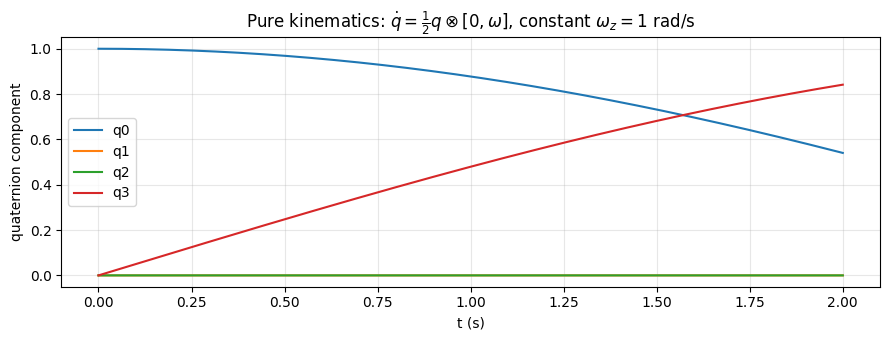

In [3]:
def integrate_kinematics_only(omega_body, dt=0.001, steps=2000):
    q = Quaternion()
    log = [q.q.copy()]
    for _ in range(steps):
        omega_quat = Quaternion(0, *omega_body)
        dq = 0.5 * omega_quat.multiply(q).q
        q = Quaternion(*(q.q + dq*dt))
        log.append(q.q.copy())
    return np.array(log)

log = integrate_kinematics_only(omega_body=[0, 0, 1.0])   # 1 rad/s yaw rate
t = np.arange(len(log)) * 0.001

fig, ax = plt.subplots(figsize=(9, 3.5))
for i, lbl in enumerate(['q0', 'q1', 'q2', 'q3']):
    ax.plot(t, log[:, i], label=lbl)
ax.set_xlabel('t (s)'); ax.set_ylabel('quaternion component')
ax.set_title(r'Pure kinematics: $\dot q = \frac{1}{2} q \otimes [0,\omega]$, constant $\omega_z=1$ rad/s')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2.3 Rigid-Body Rotational Dynamics + RK4 Integration

$$I\dot\omega = \tau - \omega\times(I\omega)$$

with $I=\mathrm{diag}(I_{xx},I_{yy},I_{zz})$ the body inertia tensor (Paper 2 values:
$I_{xx}=I_{yy}=6.5\times10^{-4}$, $I_{zz}=1.2\times10^{-3}$ kg·m²) and $\tau$ the applied torque. The
cross term $\omega\times(I\omega)$ is the **gyroscopic coupling** between axes. `QuadrotorModel` integrates
$[q,\omega]$ jointly with classical RK4, renormalizing $q$ every step (Paper 2 Eq. 18).

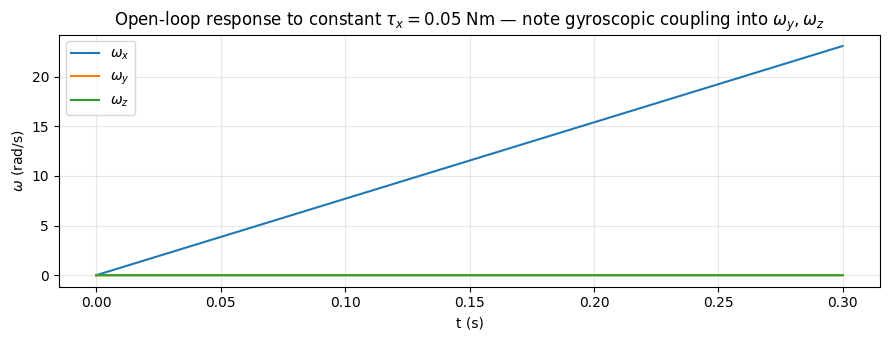

In [4]:
drone = QuadrotorModel()
tau_const = np.array([0.05, 0.0, 0.0])   # constant roll torque, no controller yet
dt = 1e-4
n = 3000

omega_log, q_log, t_log = [], [], []
for i in range(n):
    drone.step_attitude_only(tau_const, dt)
    omega_log.append(drone.omega.copy())
    q_log.append(drone.q.q.copy())
    t_log.append(i*dt)

omega_log = np.array(omega_log); t_log = np.array(t_log)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t_log, omega_log[:,0], label=r'$\omega_x$')
ax.plot(t_log, omega_log[:,1], label=r'$\omega_y$')
ax.plot(t_log, omega_log[:,2], label=r'$\omega_z$')
ax.set_xlabel('t (s)'); ax.set_ylabel(r'$\omega$ (rad/s)')
ax.set_title(r'Open-loop response to constant $\tau_x=0.05$ Nm — note gyroscopic coupling into $\omega_y,\omega_z$')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2.4 Quaternion Attitude Error & the P² Control Law

Attitude error between reference $q_{ref}$ and measured $q_{meas}$:

$$q_{err} = q_{ref}\otimes q_{meas}^{-1}, \qquad q_{meas}^{-1}=\bar q_{meas}$$

The scalar part is forced positive ($q_{err}\leftarrow -q_{err}$ if $q_{err,0}<0$) so the controller always
takes the **shortest rotational path** — avoiding the double-cover singularity where $q$ and $-q$ both
represent the same physical attitude but a naive error would spin the "long way around."

**P² law** — a cascade of an outer attitude-error loop directly onto an inner rate-damping loop, with no
separate rate-loop integrator and no Euler-angle singularities:

$$\tau = -P_q\,\vec q_{err} - P_w\,\omega,\qquad \vec q_{err}=[q_{err,1},q_{err,2},q_{err,3}]^T$$

saturated element-wise to $\pm\tau_{max}$ ($4$ Nm). This is `P2Controller.compute_error` /
`.compute_torque` in `attitude_control/p2_controller.py`, verbatim.

In [5]:
import inspect
print(inspect.getsource(P2Controller.compute_error))
print(inspect.getsource(P2Controller.compute_torque))

    def compute_error(self, q_ref, q_measured):
        q_err = q_ref.multiply(q_measured.conjugate())

        if q_err.q0 < 0:
            q_err = Quaternion(
                -q_err.q0,
                -q_err.q1,
                -q_err.q2,
                -q_err.q3
            )
        return q_err

    def compute_torque(self, q_ref, q_measured, omega):
        q_err = self.compute_error(q_ref, q_measured)

        axis_err = np.array([q_err.q1, q_err.q2, q_err.q3])

        tau = -self.Pq * axis_err - self.Pw * omega
        
        tau = np.clip(tau, -4.0, 4.0)

        return tau, axis_err



### Step-response demo (reproduces Paper 2 Fig. 3)

Paper 2's exact gains $P_q=20,\ P_w=4$, at the physics rate $dt=10^{-4}$s (10 kHz) — the rate this project's
low inertia values actually require for those gains to be stable (see the stability note below). The
reference commands step through roll → pitch → yaw.

In [6]:
Pq, Pw, NOISE_STD, DT = 20.0, 4.0, 0.1, 1e-4
TOTAL_TIME = 3.0
n_steps = int(TOTAL_TIME/DT)

def step_q_ref(t):
    if t < 0.5:   return Quaternion()
    elif t < 1.5: return Quaternion.from_euler(1.0, 0.0, 0.0)
    elif t < 2.5: return Quaternion.from_euler(0.0, 1.0, 0.0)
    else:         return Quaternion.from_euler(0.0, 0.0, 1.0)

drone = QuadrotorModel()
ctrl  = P2Controller(Pq=Pq, Pw=Pw)

t_arr = np.zeros(n_steps)
euler_actual = np.zeros((n_steps, 3))
euler_ref    = np.zeros((n_steps, 3))
torque_arr   = np.zeros((n_steps, 3))
err_mag_arr  = np.zeros(n_steps)

for i in range(n_steps):
    t = i * DT
    q_ref = step_q_ref(t)
    omega_noisy = drone.omega + np.random.normal(0, NOISE_STD, 3)
    tau, axis_err = ctrl.compute_torque(q_ref, drone.q, omega_noisy)
    drone.step_attitude_only(tau, DT)

    t_arr[i] = t
    euler_actual[i] = drone.q.to_euler()
    euler_ref[i] = q_ref.to_euler()
    torque_arr[i] = tau
    err_mag_arr[i] = np.linalg.norm(axis_err)

print(f"Max tracking error: {err_mag_arr.max():.4f}")
print(f"Max torque used:    {np.abs(torque_arr).max():.3f} Nm (limit +/-4 Nm)")

Max tracking error: 0.6324
Max torque used:    4.000 Nm (limit +/-4 Nm)


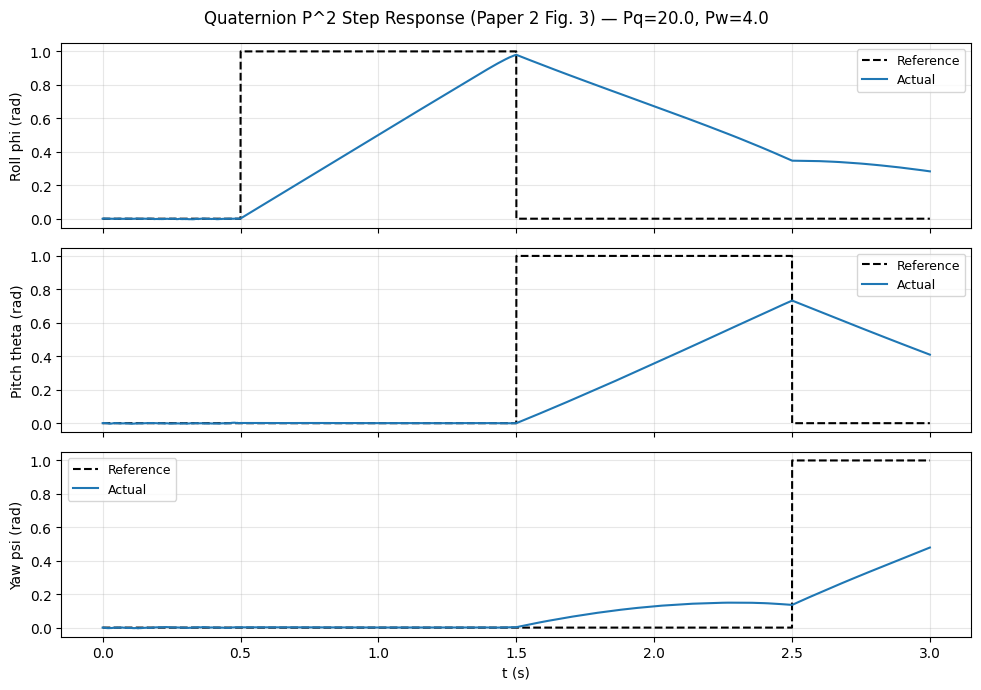

In [7]:
labels = ['Roll phi (rad)', 'Pitch theta (rad)', 'Yaw psi (rad)']
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for i in range(3):
    axes[i].plot(t_arr, euler_ref[:,i], 'k--', lw=1.5, label='Reference')
    axes[i].plot(t_arr, euler_actual[:,i], lw=1.5, label='Actual')
    axes[i].set_ylabel(labels[i]); axes[i].grid(alpha=0.3); axes[i].legend(fontsize=9)
axes[-1].set_xlabel('t (s)')
fig.suptitle(f'Quaternion P^2 Step Response (Paper 2 Fig. 3) — Pq={Pq}, Pw={Pw}')
plt.tight_layout(); plt.show()

## 2.5 Stability Note — Gains vs. Timestep

Paper 2's exact gains ($P_q=20,\ P_w=4$) with this project's inertia ($I_{xx}=I_{yy}=6.5\times10^{-4}$)
place the fast closed-loop pole beyond $-6000$ rad/s ($\approx160\,\mu$s time constant). The control law
above is therefore recomputed at the **same rate as the physics integration** ($dt=10^{-4}$s). Holding the
torque over a coarser control period lets $\omega$ build up before the controller can react — that (not
the RK4 integrator) was the actual source of divergence found during development.

In the merged simulation (notebook 3), the outer position loop runs at a coarser $dt=0.01$s, so the
inner attitude loop there uses a reduced, empirically-stable gain pair ($P_q=0.2,\ P_w=0.1$) instead —
documented as an intentional trade-off, not an oversight.

## 2.6 Outer Loop — Position & Altitude Control

The inner quaternion loop only tracks a *given* attitude; something has to produce that attitude from a
*position* target. `PositionController` (`attitude_control/position_controller.py`) is a cascading
outer loop:

$$\mathbf a_{des} = K_p\,(\mathbf p_{ref}-\mathbf p) + K_d\,(\mathbf v_{ref}-\mathbf v) + \begin{bmatrix}0\\0\\g\end{bmatrix}$$

From $\mathbf a_{des}$ (tilt-limited to $\pm45°$ from vertical):

- **Thrust magnitude:** $F_{thrust}=m\,\mathbf a_{des}\!\cdot\!\hat z_b$
- **Desired body frame:** $\hat z_b = \mathbf a_{des}/\lVert\mathbf a_{des}\rVert$, with $\hat x_b,\hat y_b$
  built from $\hat z_b$ and a yaw reference $\to$ desired quaternion $q_{des}$ via
  `Quaternion.from_rotation_matrix`.

This is exactly how the merged simulation converts "go to this 3D point" into "hold this attitude at this
thrust" for the inner P² loop.

In [8]:
pos_ctrl = PositionController(Kp_pos=(2.0,2.0,4.0), Kd_pos=(1.5,1.5,2.5), mass=1.0, g=9.81)

# Step from origin to a target 10m up and 5m over — single evaluation of the outer loop
thrust, q_des = pos_ctrl.compute(
    pos_ref=np.array([5.0, 0.0, 10.0]), pos=np.zeros(3),
    vel_ref=np.zeros(3), vel=np.zeros(3), yaw_ref=0.0
)
print(f"Commanded thrust: {thrust:.3f} N  (hover thrust = m*g = {1.0*9.81:.3f} N)")
print(f"Desired attitude (deg): {np.degrees(q_des.to_euler())}")

Commanded thrust: 30.000 N  (hover thrust = m*g = 9.810 N)
Desired attitude (deg): [ 0.         11.35195601  0.        ]


## 2.7 Summary

- `Quaternion` implements the Hamilton algebra (§2.1) needed for singularity-free attitude representation.
- `QuadrotorModel` integrates the coupled quaternion-kinematics + rigid-body-dynamics ODE (§2.2–2.3) with
  RK4 and per-step renormalization.
- `P2Controller` computes the shortest-path quaternion error and applies the cascaded P² law (§2.4),
  saturated to the paper's $\pm4$ Nm torque limit.
- `PositionController` is this project's outer loop (not in Paper 2) — it converts a 3D position/velocity
  target into the thrust + desired-attitude pair the inner loop needs (§2.6).

**Next:** `03_full_pipeline_merged_simulation.ipynb` couples this control stack to the B-Spline path
from notebook 1 and runs the complete simulation end to end.